In [128]:
from typing import Callable, Literal

import duckdb
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import ArrayLike
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import root_mean_squared_error, ndcg_score
from sklearn.model_selection import train_test_split, GridSearchCV, PredefinedSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils import check_X_y, check_array
from scipy.sparse import csr_array, issparse, spmatrix, sparray, vstack

from recommender_fm import mean_lowest_scorer, mean_lowest_rating, ndcg_p_score

In [129]:
def per_var_split_mask(
        df_sorted: pd.DataFrame,
        var: str,
        test_ratio=0.01,
        test_min_per_var=10,
):
    per_var_count = df_sorted[var].map(df_sorted[var].value_counts())
    per_var_ranks = df_sorted.groupby(var).cumcount(ascending=False)
    per_var_test_size = np.maximum(test_min_per_var, test_ratio * per_var_count)
    test_mask = per_var_ranks < per_var_test_size
    
    return test_mask

In [130]:
def per_var_temporal_split(
        X: pd.DataFrame,
        y: ArrayLike,
        var="user_id",
        time_col="timestamp",
        test_ratio=0.01,
        test_min_per_var=10,
):
    sort_indices = X.sort_values(by=[var, time_col]).index
    X_sorted = X.loc[sort_indices]
    y_sorted = pd.Series(y, index=X.index).loc[sort_indices]
    test_mask = per_var_split_mask(X_sorted, var, test_ratio, test_min_per_var)
    return X_sorted[~test_mask], X_sorted[test_mask], y_sorted[~test_mask], y_sorted[test_mask]

In [131]:
dataset = ArrayLike | spmatrix | sparray


def _predict_y_fm(X, w0, weights, factors):
    X_dot_factors = X @ factors
    X_dot_factors_squares = X ** 2 @ (factors ** 2)
    interactions = np.sum(X_dot_factors ** 2 - X_dot_factors_squares, axis=1) / 2
    linear_part = X @ weights
    return w0 + linear_part + interactions, X_dot_factors


def _process_X_y(X, y):
    X, y = check_X_y(X, y, accept_sparse=["csr"])
    if issparse(X):
        X = csr_array(X)
    return X, y


def _prepare_split_data(X, y, eval_set):
    X, y = _process_X_y(X, y)
    X_eval, y_eval = X, y
    if eval_set is not None:
        X_eval, y_eval = _process_X_y(eval_set[0], eval_set[1])
    return X, X_eval, y, y_eval


class FactorizationMachine:
    def __init__(
            self, 
            factors_num: int = 1, 
            num_recommend=5,
            max_epoch=1000,
            tol=1e-4,
            learn_rate=0.01,
            loss: str | Callable[[ArrayLike, ArrayLike], float] = "mse",
            dloss_dpred: Callable[[ArrayLike, ArrayLike], ArrayLike] | None = None,
            metric: Literal["neg_rmse", "mean_lowest_per_user", "ndcg"] = "ndcg",
            weights_penalty=0,
            factors_penalty=0,
            batch_size=1000,
            patience=10,
            random_state=None,
            verbose=False,
    ):
        self._init_loss(loss, dloss_dpred)
        self.metric = metric
        self.factors_num = factors_num
        self.num_recommend = num_recommend
        self.max_epoch = max_epoch
        self.stop_epoch = max_epoch
        self.tol = tol
        self.learn_rate = learn_rate
        self.patience = patience
        self.batch_size = batch_size
        self.random_state = random_state
        self.weights_penalty = weights_penalty
        self.factors_penalty = factors_penalty
        self.verbose = verbose
        self.fitted_ = False

    def _init_loss(self, loss, dloss_dpred):
        if loss == "mse":
            self.loss = lambda y, y_pred: np.mean((y - y_pred) ** 2)
            self.dloss_dpred = lambda y, y_pred: 2 * (y_pred - y) / y.shape[0]
        else:
            self.loss = loss
            self.dloss_dpred = dloss_dpred

    def _init_params(
            self, 
            dim: int, 
            y: ArrayLike,
            rng
    ):
        self._w0 = np.mean(y)
        self._weights = np.zeros(shape=(dim,), dtype=float)

        init_std = np.sqrt(2.0 / (dim + self.factors_num))
        self._factors = rng.normal(
            scale=init_std, 
            size=(dim, self.factors_num),
        )
        self._no_improvement_count = 0
        self._best_score = -np.inf

        self._squared_weight_grads = np.zeros(dim)
        self._squared_factor_grads = np.zeros((dim, self.factors_num))
        self._squared_w0_grads = 0.0

    def _run_epoch(self, X, y, n_samples, rng):
        permutation = rng.permutation(n_samples)
        for i in range(0, n_samples, self.batch_size):
            batch_indices = permutation[i : i + self.batch_size]
            self._update_batch(X[batch_indices], y[batch_indices])

    def _update_coef(self, coef, grad, squared_grads):
        squared_grads += np.square(grad)
        curr_learn_rate = self.learn_rate / np.sqrt(squared_grads + 1e-8)
        coef -= curr_learn_rate * grad
        return coef, squared_grads

    def _update_batch(self, X_batch, y_batch):
        y_pred_batch, X_dot_factors = self._predict(X_batch)
        dloss_dpred = self.dloss_dpred(y_batch, y_pred_batch)

        w0_grad = np.sum(dloss_dpred)
        self._w0, self._squared_w0_grads = self._update_coef(
            self._w0, w0_grad, self._squared_w0_grads,
        )

        weights_grad = X_batch.T @ dloss_dpred \
                    + 2 * self.weights_penalty * self._weights
        self._weights, self._squared_weight_grads = self._update_coef(
            self._weights, weights_grad, self._squared_weight_grads,
        )

        factor_coef_0 = X_batch.T @ (dloss_dpred[:, np.newaxis] * X_dot_factors)
        factor_coef_1 = -(X_batch.T ** 2) @ dloss_dpred
        factors_grad = factor_coef_0 \
                        + factor_coef_1[:, np.newaxis] * self._factors \
                        + 2 * self.factors_penalty * self._factors

        self._factors, self._squared_factor_grads = self._update_coef(
            self._factors, factors_grad, self._squared_factor_grads,
        )
    
    def _count_loss(self, X, y):
        y_pred = self._predict(X)[0]
        return self.loss(y_pred, y)

    def _is_converged(self, X_eval, y_eval, users=None):
        curr_score = self.score(X_eval, y_eval, users)

        if curr_score > self._best_score + self.tol:
            self._best_score = curr_score
            self._no_improvement_count = 0
        else:
            self._no_improvement_count += 1

        if self._no_improvement_count >= self.patience:
            return True
        else:
            return False

    def fit(
            self,
            X: dataset,
            y: ArrayLike,
            eval_set: tuple[ArrayLike, ArrayLike] | None = None,
            users=None,
    ):
        X_train, X_eval, y_train, y_eval = _prepare_split_data(X, y, eval_set)
        n_samples, dim = X.shape
        rng = np.random.default_rng(seed=self.random_state)

        self._init_params(dim, y_train, rng)
        best_epoch = self.stop_epoch

        for epoch in range(self.stop_epoch):
            self._run_epoch(X_train, y_train, n_samples, rng)
            if eval_set is not None:
                is_converged = self._is_converged(X_eval, y_eval, users)
                if is_converged:
                    best_epoch = epoch
                    break

            if self.verbose == True:
                print(
                    f"Epoch {epoch}, factors num {self.factors_num}, \n"
                    f"factors abs mean: {np.mean(np.abs(self._factors))}, \n"
                    f"weights abs mean: {np.mean(np.abs(self._weights))}, \n"
                    f"intercept {self._w0}, best validation {self.metric} score {self._best_score}"
                )

        if eval_set is not None:
            X_all = vstack([X_train, X_eval])
            y_all = np.concatenate([y_train, y_eval])
            self.stop_epoch = best_epoch
            return self.fit(X_all, y_all, None, None)

        self.fitted_ = True
        return self

    def _predict(self, X):
        return _predict_y_fm(X, self._w0, self._weights, self._factors)

    def predict(self, X):
        X = check_array(X, accept_sparse=["csr"])
        if issparse(X):
            X = csr_array(X)
        return self._predict(X)[0]

    def score(self, X, y, users=None):
        y_pred = self.predict(X)
        if self.metric == "neg_rmse":
            return -root_mean_squared_error(y, y_pred)
        if self.metric == "mean_lowest_per_user":
            return mean_lowest_rating(
                y, y_pred, users=users, num_recommend=self.num_recommend
            )
        if self.metric == "ndcg":
            return ndcg_p_score(y, y_pred, users, p=self.num_recommend)
        else:
            raise NotImplementedError



## Movies dataset

MovieLens100k and MovieLens1M can't be used together -- users' ids don't match.

In [132]:
with duckdb.connect("/home/maria-khanina/mkgit/movies_project/data/database.duckdb", read_only=True) as db_conn:
    ratings_df = db_conn.execute("""
        SELECT *
        FROM ratings INNER JOIN movies USING (movie_id)
    """).df()


In [133]:
ratings_df.head()

,user_id,movie_id,rating,timestamp,title,genres
0,1945,1248,3,974692298,Touch of Evil (1958),Crime|Film-Noir|Thriller
1,1945,1252,3,974691937,Chinatown (1974),Film-Noir|Mystery|Thriller
2,1945,589,3,974692787,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller
3,1945,6,3,974693183,Heat (1995),Action|Crime|Thriller
4,1945,1267,2,974692090,"Manchurian Candidate, The (1962)",Film-Noir|Thriller


In [134]:
ratings_df.shape

(1000209, 6)

In [135]:
ratings_df.isna().sum()

user_id      0
movie_id     0
rating       0
timestamp    0
title        0
genres       0
dtype: int64

In [136]:
ratings_df["rating"].value_counts().sort_index()

rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

In [137]:
ratings_df["movie_id"].min(), ratings_df["user_id"].min()

(np.int64(1), np.int64(1))

In [138]:
ratings_df["movie_id"].max(), ratings_df["user_id"].max()

(np.int64(3952), np.int64(6040))

In [139]:
ratings_df["movie_id"].nunique(), ratings_df["user_id"].nunique()

(3706, 6040)

In [140]:
groupby_user = ratings_df.groupby("user_id")
time_range = groupby_user["timestamp"].max() - groupby_user["timestamp"].min()
days_range = time_range / (60 * 60 * 24)

In [141]:
days_range.min(), days_range.median(), days_range.max()

(np.float64(0.0012268518518518518),
 np.float64(0.04708912037037037),
 np.float64(1032.9605555555556))

In [142]:
(days_range > 7).mean()

np.float64(0.29751655629139073)

In [143]:
X_train_all, X_test, y_train_all, y_test = per_var_temporal_split(
    X=ratings_df.drop(columns="rating"),
    y=ratings_df["rating"],
    var="user_id",
    time_col="timestamp",
    test_ratio=0.01,
    test_min_per_var=10,
)

In [144]:
X_train_all.shape, X_test.shape, y_train_all.shape, y_test.shape

((939685, 5), (60524, 5), (939685,), (60524,))

In [145]:
X_train_all["user_id"].nunique(), X_test["user_id"].nunique()

(6040, 6040)

In [146]:
(X_train_all.groupby("user_id")["timestamp"].max() > X_test.groupby("user_id")["timestamp"].min()).sum()

np.int64(0)

In [147]:
X_train_big, X_outer_val, y_train_big, y_outer_val = per_var_temporal_split(
    X_train_all,
    y_train_all,
    var="user_id",
    time_col="timestamp",
    test_ratio=0.01,
    test_min_per_var=10,
)

In [148]:
X_train, X_val, y_train, y_val = per_var_temporal_split(
    X_train_big,
    y_train_big,
    var="user_id",
    time_col="timestamp",
    test_ratio=0.01,
    test_min_per_var=10,
)

### Median number of movies rated per user:

In [149]:
X_train.groupby("user_id").size().median()

np.float64(86.0)

In [150]:
X_train.groupby("movie_id").size().median()

np.float64(104.0)

In [151]:
records_per_entity = pd.concat((
        X_train.groupby("user_id").size(), 
        X_train.groupby("movie_id").size()
))

In [152]:
records_per_entity.median()

np.float64(91.0)

([<matplotlib.axis.XTick at 0x7f5de37974a0>,
 [Text(0, 0, '0'),
  Text(50, 0, '50'),
  Text(100, 0, '100'),
  Text(150, 0, '150'),
  Text(200, 0, '200'),
  Text(250, 0, '250'),
  Text(300, 0, '300'),
  Text(350, 0, '350'),
  Text(400, 0, '400'),
  Text(450, 0, '450'),
  Text(500, 0, '500'),
  Text(550, 0, '550'),
  Text(600, 0, '600'),
  Text(650, 0, '650'),
  Text(700, 0, '700'),
  Text(750, 0, '750'),
  Text(800, 0, '800'),
  Text(850, 0, '850'),
  Text(900, 0, '900'),
  Text(950, 0, '950'),
  Text(1000, 0, '1000'),
  Text(1050, 0, '1050'),
  Text(1100, 0, '1100'),
  Text(1150, 0, '1150'),
  Text(1200, 0, '1200'),
  Text(1250, 0, '1250'),
  Text(1300, 0, '1300'),
  Text(1350, 0, '1350'),
  Text(1400, 0, '1400'),
  Text(1450, 0, '1450'),
  Text(1500, 0, '1500'),
  Text(1550, 0, '1550'),
  Text(1600, 0, '1600'),
  Text(1650, 0, '1650'),
  Text(1700, 0, '1700'),
  Text(1750, 0, '1750'),
  Text(1800, 0, '1800'),
  Text(1850, 0, '1850'),
  Text(1900, 0, '1900'),
  Text(1950, 0, '1950')])

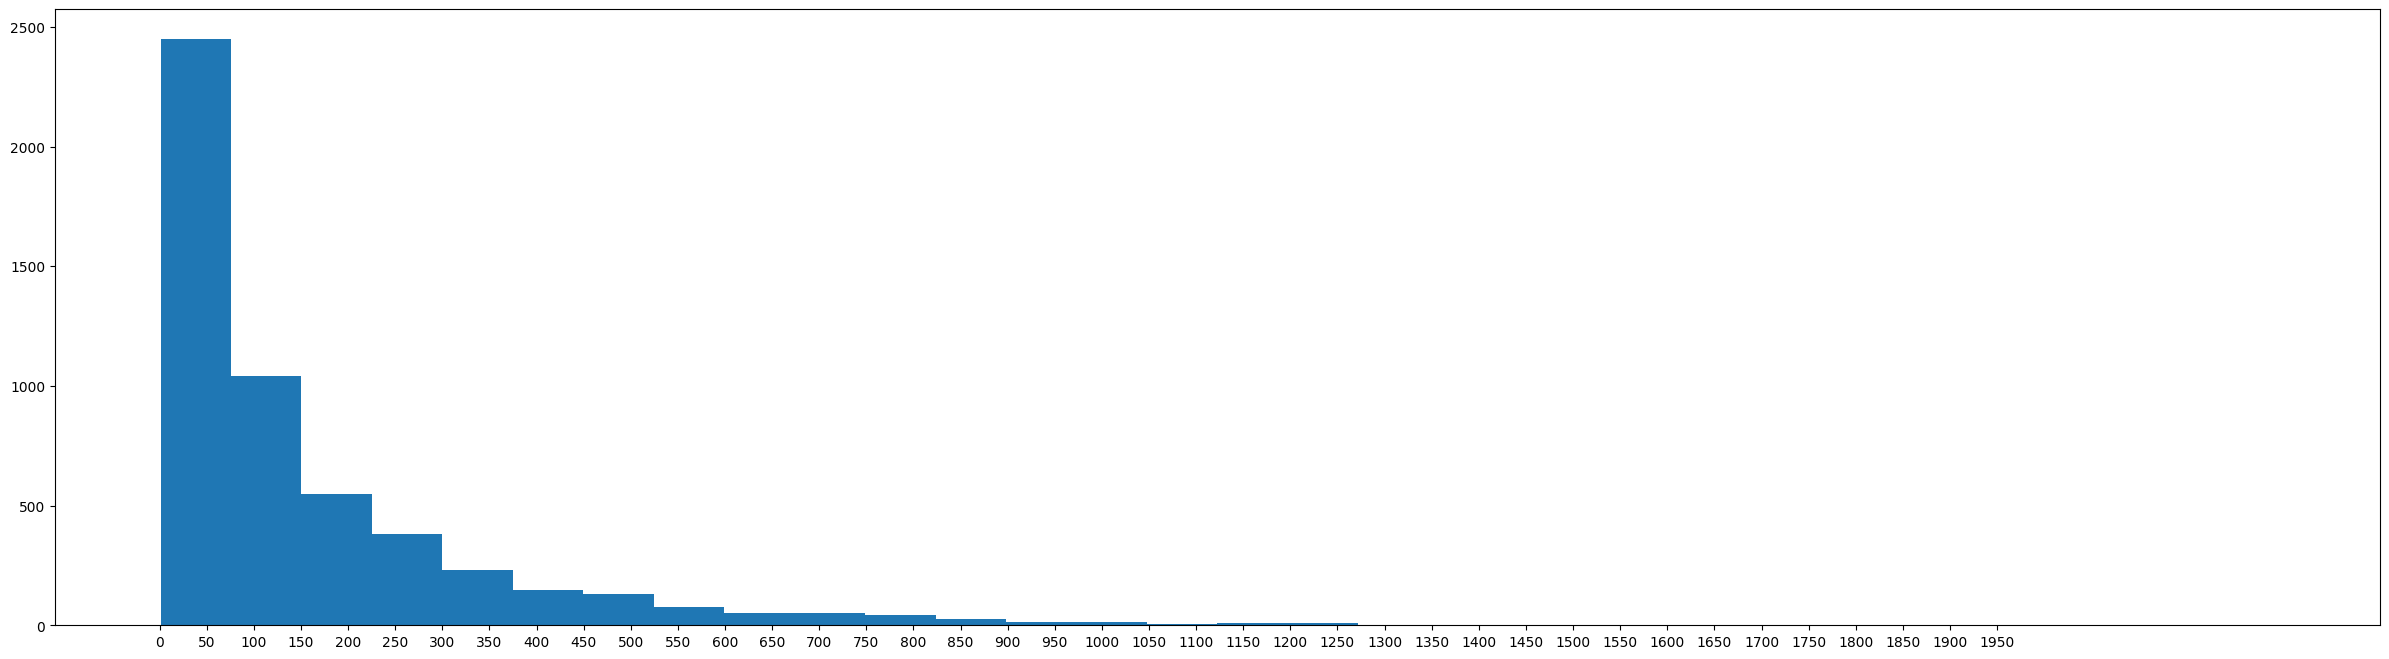

In [153]:
d = X_train.groupby("user_id").size()
plt.figure(figsize=(30, 8))
plt.hist(d, bins=30)
plt.xticks(range(0, 2000, 50))

### Average train rating as prediction

In [154]:
df_train = pd.concat((X_train_big, y_train_big), axis="columns")
avg_total = df_train["rating"].mean()
avg_train_ratings = df_train.groupby("movie_id", as_index=False)["rating"].mean()
avg_train_ratings.columns = ["movie_id", "avg_movie_rating"]

In [155]:
df_outer_val = pd.merge(left=X_outer_val, right=avg_train_ratings, on="movie_id", how="left")
df_outer_val["avg_movie_rating"] = df_outer_val["avg_movie_rating"].fillna(avg_total)

In [156]:
root_mean_squared_error(y_outer_val, df_outer_val["avg_movie_rating"])

0.996853495827109

In [157]:
mean_lowest_rating(
    true_ratings=y_outer_val,
    predicted_ratings=df_outer_val["avg_movie_rating"],
    users=df_outer_val["user_id"],
    num_recommend=5,
)

np.float64(3.422222222222222)

In [158]:
ndcg_p_score(
    y_outer_val,
    df_outer_val["avg_movie_rating"],
    df_outer_val["user_id"],
    p=5,
)

np.float64(0.12621708096534973)

### Factorization Machine with only encoded user_id and movie_id as features

In [159]:
all_users = np.sort(X_train["user_id"].unique())
all_movies = np.sort(X_train["movie_id"].unique())

In [160]:
basic_transformer = ColumnTransformer(
    transformers=[
        (
            "encode_id",
            OneHotEncoder(
                categories=[all_users, all_movies],
                handle_unknown="ignore",
                min_frequency=10,
            ),
            ["user_id", "movie_id"],
        ),
    ],
    remainder="drop",
)

In [161]:
basic_fm = FactorizationMachine(
    verbose=True,
    metric="mean_lowest_per_user",
    tol=1e-4,
    factors_num=20,
)

In [162]:
X_train_transformed = basic_transformer.fit_transform(X_train)
X_val_transformed = basic_transformer.transform(X_val)
X_outer_val_transformed = basic_transformer.transform(X_outer_val)

In [163]:
basic_fm.fit(
    X_train_transformed, 
    y_train,
    eval_set=(X_val_transformed, y_val),
    users=X_val["user_id"],
)

Epoch 0, factors num 20, 
factors abs mean: 0.05131411445029138, 
weights abs mean: 0.06574401513617159, 
intercept 3.5096976443753896, best validation mean_lowest_per_user score 2.8535438360765872
Epoch 1, factors num 20, 
factors abs mean: 0.07829534097609635, 
weights abs mean: 0.0832417832642088, 
intercept 3.4657708401629024, best validation mean_lowest_per_user score 2.8696674504534765
Epoch 2, factors num 20, 
factors abs mean: 0.09115383143237016, 
weights abs mean: 0.09288195990822382, 
intercept 3.446950552698919, best validation mean_lowest_per_user score 2.876049714477662
Epoch 3, factors num 20, 
factors abs mean: 0.09927751259033175, 
weights abs mean: 0.0993385804832321, 
intercept 3.438874155071491, best validation mean_lowest_per_user score 2.8820960698689957
Epoch 4, factors num 20, 
factors abs mean: 0.1051177140847295, 
weights abs mean: 0.10411835776399826, 
intercept 3.4343607865535306, best validation mean_lowest_per_user score 2.8825999328182736
Epoch 5, factors

In [164]:
val_predictions = basic_fm.predict(X_outer_val_transformed)

In [165]:
mean_lowest_rating(y_outer_val, val_predictions, X_outer_val["user_id"], 5)

np.float64(2.9480132450331125)

In [166]:
y_pred_clipped = np.clip(val_predictions, 1, 5)
root_mean_squared_error(y_outer_val, y_pred_clipped)

0.9279610194609892

In [167]:
ndcg_p_score(y_outer_val, val_predictions, X_outer_val["user_id"], p=5)

np.float64(0.7952171634049567)

In [168]:
basic_fm.metric = "ndcg"
basic_fm.stop_epoch = basic_fm.max_epoch
basic_fm.fit(
    X_train_transformed,
    y_train, 
    eval_set=(X_val_transformed, y_val),
    users=X_val["user_id"],
)

Epoch 0, factors num 20, 
factors abs mean: 0.04513481502381015, 
weights abs mean: 0.06626095521427106, 
intercept 3.5098975112060917, best validation ndcg score 0.7777249479371647
Epoch 1, factors num 20, 
factors abs mean: 0.07355943542209746, 
weights abs mean: 0.08456101468116317, 
intercept 3.4634582831806378, best validation ndcg score 0.7823552845799818
Epoch 2, factors num 20, 
factors abs mean: 0.08780467911553612, 
weights abs mean: 0.0944693516607566, 
intercept 3.4447951655752362, best validation ndcg score 0.7852553912354217
Epoch 3, factors num 20, 
factors abs mean: 0.09690331672449318, 
weights abs mean: 0.10101345959437959, 
intercept 3.434811342320149, best validation ndcg score 0.7873496438120673
Epoch 4, factors num 20, 
factors abs mean: 0.10351872919447652, 
weights abs mean: 0.10576713854749198, 
intercept 3.4219582693491684, best validation ndcg score 0.7887570945379254
Epoch 5, factors num 20, 
factors abs mean: 0.10872242962228915, 
weights abs mean: 0.109483

In [169]:
val_predictions = basic_fm.predict(X_outer_val_transformed)
ndcg_p_score(y_outer_val, val_predictions, X_outer_val["user_id"], p=5)

np.float64(0.7932123029888434)

In [170]:
mean_lowest_rating(y_outer_val, val_predictions, X_outer_val["user_id"], 5)

np.float64(2.94205298013245)

In [42]:
y_pred_clipped = np.clip(val_predictions, 1, 5)
root_mean_squared_error(y_outer_val, y_pred_clipped)

0.9224996880685958

In [171]:
factors_grid = [(10, 0), (30, 0), (30, 0.0001)]
scores = []

for p in [3, 4, 5]:
    for n_factors, factors_penalty in factors_grid:
        basic_fm.factors_num = n_factors
        basic_fm.factors_penalty = factors_penalty
        basic_fm.stop_epoch = basic_fm.max_epoch
        basic_fm.fit(
            X_train_transformed,
            y_train,
            eval_set=(X_val_transformed, y_val),
            users=X_val["user_id"],
        )
        y_pred = basic_fm.predict(X_outer_val_transformed)
        ndcg_ = ndcg_p_score(y_outer_val, y_pred, X_outer_val["user_id"], p)
        rmse = root_mean_squared_error(y_outer_val, y_pred)
        mean_lowest_rating_ = mean_lowest_rating(y_outer_val, y_pred, X_outer_val["user_id"], p)
        scores.append({
            "p": p,
            "n_factors": n_factors,
            "factors_penalty": factors_penalty,
            "ndcg_p_score": ndcg_,
            "mean_lowest_rating": mean_lowest_rating_,
            "rmse": rmse,
            "stop_epoch": basic_fm.stop_epoch,
        })

Epoch 0, factors num 10, 
factors abs mean: 0.054512976311080256, 
weights abs mean: 0.06655152917571405, 
intercept 3.5232965590392364, best validation ndcg score 0.7782028458392493
Epoch 1, factors num 10, 
factors abs mean: 0.08799330583103239, 
weights abs mean: 0.08652781023445463, 
intercept 3.489358098039879, best validation ndcg score 0.7808844542652982
Epoch 2, factors num 10, 
factors abs mean: 0.10521842161651028, 
weights abs mean: 0.09822319653640153, 
intercept 3.4739444575094645, best validation ndcg score 0.7827159800604285
Epoch 3, factors num 10, 
factors abs mean: 0.11611768208230352, 
weights abs mean: 0.10629048103735793, 
intercept 3.4646608393692375, best validation ndcg score 0.7838754236956675
Epoch 4, factors num 10, 
factors abs mean: 0.12390866810173515, 
weights abs mean: 0.11234725124277863, 
intercept 3.4572564732997275, best validation ndcg score 0.7850126608575559
Epoch 5, factors num 10, 
factors abs mean: 0.12993970858236065, 
weights abs mean: 0.1171

In [172]:
pd.DataFrame(scores)

,p,n_factors,factors_penalty,ndcg_p_score,mean_lowest_rating,rmse,stop_epoch
0,3,10,0.0000,0.755682,3.352649,0.930653,121
1,3,30,0.0000,0.759327,3.355298,0.930183,81
2,3,30,0.0001,0.735826,3.281457,0.951410,60
3,4,10,0.0000,0.771258,3.120530,0.932438,111
4,4,30,0.0000,0.777733,3.129305,0.929043,58
5,4,30,0.0001,0.754968,3.061258,0.950298,69
6,5,10,0.0000,0.792528,2.932285,0.928736,127
7,5,30,0.0000,0.797305,2.956954,0.928336,78
8,5,30,0.0001,0.775739,2.876159,0.950920,63


## Test scores:

In [173]:
best_fm = FactorizationMachine(factors_num=30, max_epoch=60)

X_train_all_transformed = basic_transformer.fit_transform(X_train_all, y_train_all)
X_test_transformed = basic_transformer.transform(X_test)
best_fm.fit(X_train_all_transformed, y_train_all, users=X_train_all["user_id"])
test_pred = best_fm.predict(X_test_transformed)


In [174]:
ndcg_p_score(y_test, test_pred, X_test["user_id"])

np.float64(0.8020009163870198)

In [175]:
mean_lowest_rating(y_test, test_pred, X_test["user_id"], 5)

np.float64(2.9274834437086095)

In [176]:
root_mean_squared_error(y_test, test_pred)

0.9285468092063428

30 factors without regularization produce best results.

### Adding genres:

In [177]:
transformer_with_genres = ColumnTransformer(
    transformers=[
        (
            "extract_genres",
            CountVectorizer(
                input="content",
                tokenizer=lambda x:x.split("|"),
                binary=True,
            ),
            "genres"
        ),
        (
            "encode_id",
            OneHotEncoder(
                categories=[all_users, all_movies],
                handle_unknown="ignore",
                min_frequency=10,
            ),
            ["user_id", "movie_id"],
        ),
    ],
    remainder="drop",
)

In [178]:
X_train_transformed = transformer_with_genres.fit_transform(X_train)
X_val_transformed = transformer_with_genres.transform(X_val)
X_outer_val_transformed = transformer_with_genres.transform(X_outer_val)

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [179]:
basic_fm.metric = "ndcg"
basic_fm.factors_penalty = 0
basic_fm.factors_num = 40
basic_fm.fit(
    X_train_transformed,
    y_train,
    eval_set=(X_val_transformed, y_val),
    users=X_val["user_id"],
)

Epoch 0, factors num 40, 
factors abs mean: 0.03377080971944672, 
weights abs mean: 0.03397882637419522, 
intercept 3.419312636928739, best validation ndcg score 0.7852808018359924
Epoch 1, factors num 40, 
factors abs mean: 0.037196446771577706, 
weights abs mean: 0.037622684160371185, 
intercept 3.39297745958173, best validation ndcg score 0.7876647439102105
Epoch 2, factors num 40, 
factors abs mean: 0.03923789040533887, 
weights abs mean: 0.039561174367194134, 
intercept 3.3827866988312834, best validation ndcg score 0.7876647439102105
Epoch 3, factors num 40, 
factors abs mean: 0.040744316252537265, 
weights abs mean: 0.040865554237951095, 
intercept 3.3706579446677427, best validation ndcg score 0.7888786364210488
Epoch 4, factors num 40, 
factors abs mean: 0.04197951776559887, 
weights abs mean: 0.04185931824930258, 
intercept 3.359243385312098, best validation ndcg score 0.7888786364210488
Epoch 5, factors num 40, 
factors abs mean: 0.043056677671384415, 
weights abs mean: 0.04

In [180]:
val_predictions = basic_fm.predict(X_outer_val_transformed)
ndcg_p_score(y_outer_val, val_predictions, X_outer_val["user_id"], p=5)

np.float64(0.7875052726041707)

In [181]:
mean_lowest_rating(y_outer_val, val_predictions, X_outer_val["user_id"], 5)

np.float64(2.909933774834437)

In [182]:
y_pred_clipped = np.clip(val_predictions, 1, 5)
root_mean_squared_error(y_outer_val, y_pred_clipped)

0.9325848283489644

### Factorization Machine with user's preferences added to features

In [183]:
class UserHistoryTransformer(TransformerMixin, BaseEstimator):
    def __init__(
            self, 
            user_col="user_id",
            item_col="movie_id",
            rating_max=5.0,
    ):
        self.user_col = user_col
        self.item_col = item_col
        self.rating_max = rating_max

    def fit(self, X, y):
        y_scaled = y / self.rating_max
        self._user_history = csr_array(
            (y_scaled, (X[self.user_col], X[self.item_col])),
        )
        return self
    
    def transform(self, X):
        users = X[self.user_col].values
        items = X[self.item_col].values
        
        X_history = self._user_history[users].copy()
        X_history[np.arange(len(X)), items] = 0
        X_history.eliminate_zeros()
        
        return X_history


### Testing transformer works as expected:

In [184]:
X_transformed = UserHistoryTransformer().fit(X_train, y_train).transform(X_train)

In [185]:
row_idx = 239
user_id = X_train.iloc[row_idx]["user_id"]
movie_id = X_train.iloc[row_idx]["movie_id"]
actual_rating = y_train.iloc[row_idx] / 5.0
one_row = X_transformed[row_idx].toarray()
one_row

array([0., 0., 0., ..., 0., 0., 0.], shape=(3953,))

In [186]:
user_id, movie_id

(np.int64(5), np.int64(581))

In [187]:
assert one_row[movie_id] == 0

In [188]:
favorite_movie = np.argmax(one_row == 1)
movie_rated_1 = np.argmax(one_row == 0.2)
assert ratings_df[(ratings_df["user_id"] == user_id) & (ratings_df["movie_id"] == favorite_movie)]["rating"].min() == 5
assert ratings_df[(ratings_df["user_id"] == user_id) & (ratings_df["movie_id"] == movie_rated_1)]["rating"].min() == 1

### Training model:

In [189]:
transformer = ColumnTransformer(
    transformers=[
        ("extract_history", UserHistoryTransformer(), ["user_id", "movie_id"]),
        (
            "encode", 
            OneHotEncoder(
                categories=[all_users, all_movies],
                handle_unknown="ignore",
                min_frequency=10,
            ),
            ["user_id", "movie_id"],
        ),
    ],
    remainder="drop",
    verbose=True,
)

In [190]:
fm_with_history = Pipeline(
    steps=[
        ("transform", transformer),
        ("predict", FactorizationMachine(
            metric="ndcg",
            factors_num=50,
            weights_penalty=0,
            factors_penalty=0,
            verbose=True,
        ))
    ],
    verbose=True,
)

In [191]:
X_train_transformed = fm_with_history[:-1].fit_transform(X_train, y_train)
X_val_transformed = fm_with_history[:-1].transform(X_val)

[ColumnTransformer]  (1 of 2) Processing extract_history, total=  19.1s
[ColumnTransformer] ........ (2 of 2) Processing encode, total=   0.3s
[Pipeline] ......... (step 1 of 1) Processing transform, total=  39.8s


/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


In [192]:
fm_with_history[-1].fit(X_train_transformed, y_train, users=X_val["user_id"], eval_set=(X_val_transformed, y_val))

Epoch 0, factors num 50, 
factors abs mean: 0.027978092594515867, 
weights abs mean: 0.03690570044705389, 
intercept 3.5660416041010166, best validation ndcg score 0.7533584813177893
Epoch 1, factors num 50, 
factors abs mean: 0.03128900879025034, 
weights abs mean: 0.04260622916009185, 
intercept 3.5712925599127057, best validation ndcg score 0.7677060619119387
Epoch 2, factors num 50, 
factors abs mean: 0.03318622527144495, 
weights abs mean: 0.04584151655447692, 
intercept 3.5737576997301868, best validation ndcg score 0.7747750347815304
Epoch 3, factors num 50, 
factors abs mean: 0.03453654425090155, 
weights abs mean: 0.048045049728033515, 
intercept 3.5751467034055153, best validation ndcg score 0.778912206394963
Epoch 4, factors num 50, 
factors abs mean: 0.035596366498322214, 
weights abs mean: 0.049712851102005004, 
intercept 3.575964040425091, best validation ndcg score 0.7808216386638931
Epoch 5, factors num 50, 
factors abs mean: 0.03647532304618897, 
weights abs mean: 0.05

In [193]:
y_pred = fm_with_history.predict(X_outer_val)

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


In [194]:
y_pred_clipped = np.clip(y_pred, 1, 5)
root_mean_squared_error(y_outer_val, y_pred_clipped)

0.9382544091839989

In [195]:
mean_lowest_rating(y_outer_val, y_pred, X_outer_val["user_id"], 5)

np.float64(2.9193708609271525)

In [196]:
from sklearn.decomposition import NMF

matr_fact = NMF(init="nndsvd", verbose=100)

user_preferences = pd.pivot_table(
    data=pd.concat((X_train, y_train), axis="columns"),
    index="user_id",
    columns="movie_id",
    values="rating",
    fill_value=0,
)

for n_components in [10, 20, 30]:
    matr_fact.set_params(n_components=n_components)
    matr_fact.fit(user_preferences)
    


violation: 1.0
violation: 0.503647380927305
violation: 0.35279308285751415
violation: 0.2600795338005865
violation: 0.19854224373099702
violation: 0.15695619960143112
violation: 0.1281774136823678
violation: 0.10900623868677739
violation: 0.094867505725448
violation: 0.08357115054275595
violation: 0.0737377430101733
violation: 0.06507090355293345
violation: 0.05751932514025419
violation: 0.05122525220649727
violation: 0.04583411302341486
violation: 0.04141701395140493
violation: 0.03783701681894106
violation: 0.03499883646946545
violation: 0.03276346735576491
violation: 0.030985259336965002
violation: 0.029608153149102548
violation: 0.028668960036438696
violation: 0.02807205061901483
violation: 0.02771270984820152
violation: 0.027565631007106337
violation: 0.02762079840236506
violation: 0.027823720051809234
violation: 0.028107228766026466
violation: 0.028462199453319986
violation: 0.028868192911902645
violation: 0.02916839598113049
violation: 0.02929633393296785
violation: 0.0292380207

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


violation: 1.0
violation: 0.4083235740280209
violation: 0.2904877971283443
violation: 0.22222340007403654
violation: 0.17301306824629542
violation: 0.13905729824351104
violation: 0.11666826102005402
violation: 0.10092615180759659
violation: 0.0892331451340771
violation: 0.08040833748197082
violation: 0.07395853811010938
violation: 0.0690304088473654
violation: 0.06507316241526319
violation: 0.06153940571646464
violation: 0.05849702170271143
violation: 0.05571561791815624
violation: 0.052792976539773696
violation: 0.04986154207586115
violation: 0.046648664521155556
violation: 0.043213715866399785
violation: 0.03987039101080275
violation: 0.036793616138161234
violation: 0.033940163245648636
violation: 0.031357486629673775
violation: 0.029028603969057418
violation: 0.027075315113527842
violation: 0.025406370594795172
violation: 0.023955952455258094
violation: 0.022619243042824692
violation: 0.021377196799043277
violation: 0.020207677176852668
violation: 0.01909504943558041
violation: 0.01

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


violation: 1.0
violation: 0.371237191876401
violation: 0.2630281079941193
violation: 0.20308705967693277
violation: 0.16166953926661584
violation: 0.130670028537065
violation: 0.10790455825205846
violation: 0.09014492583390349
violation: 0.07597473236001508
violation: 0.06546615642617902
violation: 0.05735360049490925
violation: 0.05083493884512137
violation: 0.04555269147144048
violation: 0.041207239651599
violation: 0.03745953855550734
violation: 0.03415313558584103
violation: 0.031209160465753765
violation: 0.028654331407456612
violation: 0.02651020772036613
violation: 0.02472312130863077
violation: 0.023285449270648892
violation: 0.02212075900859556
violation: 0.02124526354520109
violation: 0.020592751335068667
violation: 0.020039403547563
violation: 0.019507127393335412
violation: 0.018988390766272387
violation: 0.018535161587978882
violation: 0.01809128333493122
violation: 0.017633792121614617
violation: 0.01717435200159002
violation: 0.016648989979380573
violation: 0.01618929230

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


In [197]:
rng = np.random.default_rng()
toy_shape = (1000, 10)
factors_num = 4
X = rng.normal(size=toy_shape)

intercept = -100
weights = np.ones(shape=(X.shape[1],))
factors = rng.normal(size=(X.shape[1], factors_num))

y = _predict_y_fm(X, intercept, weights, factors)[0]
y += rng.normal(scale=abs(y.mean()) * 0.05)

In [198]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, train_size=0.5)

fm = FactorizationMachine(
    random_state=42, 
    batch_size=300,
    learn_rate=0.1,
    factors_num=20,
    metric="neg_rmse",
)

fm.fit(X_train, y_train, eval_set=(X_val, y_val))

In [199]:
fm.stop_epoch

167

In [200]:
fm.score(X_test, y_test)

-3.6175488265482555e-05

Text(0, 0.5, 'FM prediction')

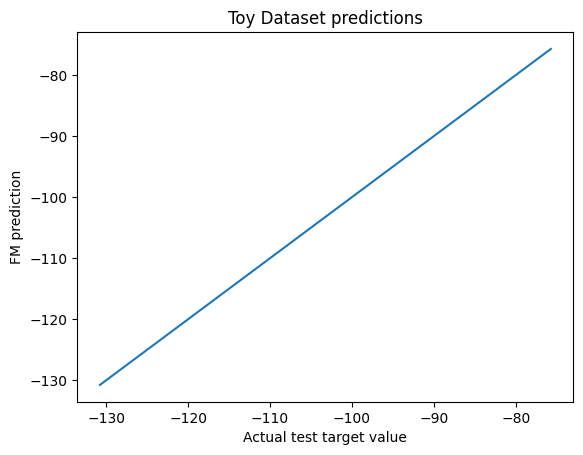

In [201]:
y_pred = fm.predict(X_test)

sns.lineplot(x=y_test, y=y_pred)
plt.title("Toy Dataset predictions")
plt.xlabel("Actual test target value")
plt.ylabel("FM prediction")
